<h4>Memory & Threads in Conversational Agentic AI Systems in LangGraph</h4>

In [7]:
#Setup Environment Variables
from dotenv import load_dotenv, find_dotenv
import os
load_dotenv()

True

In [8]:
open_api_key = os.getenv('OPENAI_API_KEY')
tavily_api_key = os.getenv('TAVILY_API_KEY')

In [9]:
from typing import TypedDict, Annotated
from langgraph.graph.message import add_messages
class State(TypedDict):
    messages: Annotated[list,add_messages]

<h5>Augment the LLM with tools</h5>

Here we define our custom search tool and then bind it to the LLM to augment the LLM

In [10]:
from langchain_openai import ChatOpenAI
from langchain_community.utilities.tavily_search import TavilySearchAPIWrapper
from langchain_core.tools import tool
llm = ChatOpenAI(model="gpt-4o", temperature=0)
tavily_search = TavilySearchAPIWrapper()
@tool
def search_web(query: str, num_results=5):
    """Search the web for a query. Userful for general information or general news"""
    results = tavily_search.raw_results(query=query,
                                        max_results=num_results,
                                        search_depth='advanced',
                                        include_raw_content=True)
    return results

tools = [search_web]
llm_with_tools = llm.bind_tools(tools=tools)

/var/folders/y4/j6_cks6j2fb8p7zcm0hyft6r0000gn/T/ipykernel_71367/1949398993.py:2: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.utilities.tavily_search import TavilySearchAPIWrapper


<h5>Build Agentic Graph with In-Memory Persistence</h5>

In [ ]:
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.checkpoint.memory import MemorySaver
from langchain_core.messages import trim_messages

# Augmented LLM with Tools Node function
def tool_calling_llm(state: State):
    messages = trim_messages(
            state["messages"],
            max_tokens=12700,
            strategy="last",
            token_counter=ChatOpenAI(model="gpt-4o"),
            include_system=True, # not necessary here as we send the sys prompt separately
            allow_partial=True,
    )
    return {"messages": [llm_with_tools.invoke(messages)]}

In [30]:
# Build the graph
builder = StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools=tools))
builder.add_edge(START, "tool_calling_llm")

# Conditional Edge
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from LLM is a tool call -> tools_condition routes to tools
    # If the latest message (result) from LLM is a not a tool call -> tools_condition routes to END
    tools_condition,
    ["tools", END]
)
builder.add_edge("tools", "tool_calling_llm") # this is the key feedback loop
builder.add_edge("tools", END)

# add in-memory persistence (transient memory)
memory = MemorySaver()
agent_inmem = builder.compile(checkpointer=memory)

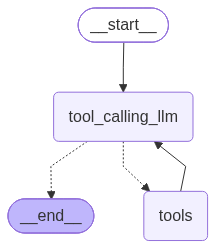

In [30]:
agent_inmem

<h5>Test Agent with In-Memory Persistence</h5>

In [31]:
uid = 'user001'
config = {"configurable": {"thread_id": uid}}

In [32]:
user_input = "Explain AI in 1 line"
for event in agent_inmem.stream(input={"messages": user_input},
                          config=config,
                          stream_mode='values'):
    event['messages'][-1].pretty_print()

================================ Human Message =================================

Explain AI in 1 line
================================== Ai Message ==================================

AI, or Artificial Intelligence, is the simulation of human intelligence processes by machines, especially computer systems, to perform tasks such as learning, reasoning, and problem-solving.


In [34]:
user_input = "Do the same for ML"
for event in agent_inmem.stream(input={"messages": user_input},
                          config=config,
                          stream_mode='values'):
    event['messages'][-1].pretty_print()

================================ Human Message =================================

Do the same for ML
================================== Ai Message ==================================

Machine Learning (ML) is a subset of AI that involves the use of algorithms and statistical models to enable computers to learn from and make predictions or decisions based on data.


In [35]:
uid = 'user002'
config = {"configurable": {"thread_id": uid}}

In [36]:
user_input = "Tell me 3 latest OpenAI product releases"
for event in agent_inmem.stream(input={"messages": user_input},
                          config=config,
                          stream_mode='values'):
    event['messages'][-1].pretty_print()

================================ Human Message =================================

Tell me 3 latest OpenAI product releases
================================== Ai Message ==================================
Tool Calls:
  search_web (call_VFPb4lf9xVrXxecOPMzNFOQ3)
 Call ID: call_VFPb4lf9xVrXxecOPMzNFOQ3
  Args:
    query: latest OpenAI product releases
    num_results: 3
================================= Tool Message =================================
Name: search_web

{"query": "latest OpenAI product releases", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://releasebot.io/updates/openai", "title": "OpenAI Release Notes - September 2026 Latest Updates - Releasebot", "content": "OpenAI releases GPT-6 Astra, its most capable model for work, now available in ChatGPT Work, Codex, and the API. It brings stronger computer use, coding, safety, and enterprise controls, plus new desktop plugins and more efficient pricing for demanding business tasks.\n\n  ### 

In [38]:
user_input = "do the same for claude releases in 100 words"
for event in agent_inmem.stream(input={"messages": user_input},
                          config=config,
                          stream_mode='values'):
    event['messages'][-1].pretty_print()

================================ Human Message =================================

do the same for claude releases in 100 words


RateLimitError: Error code: 429 - {'error': {'message': 'Request too large for gpt-4o in organization org-hCWCzoEpsjFSbmwO90OOvRIk on tokens per min (TPM): Limit 30000, Requested 92261. The input or output tokens must be reduced in order to run successfully. Visit https://platform.openai.com/account/rate-limits to learn more.', 'type': 'tokens', 'param': None, 'code': 'rate_limit_exceeded'}}

In [17]:
uid = 'user001'
config = {"configurable": {"thread_id": uid}}
user_input = "what did we discuss so far"
for event in agent_inmem.stream(input={"messages": user_input},
                          config=config,
                          stream_mode='values'):
    event['messages'][-1].pretty_print()

================================ Human Message =================================

what did we discuss so far
================================== Ai Message ==================================

We discussed the definition of AI (Artificial Intelligence) in one line, where I provided a brief explanation of AI as the simulation of human intelligence processes by machines to perform tasks that typically require human intelligence.


In [39]:
uid = 'user002'
config = {"configurable": {"thread_id": uid}}
user_input = "what did we discuss so far"
for event in agent_inmem.stream(input={"messages": user_input},
                          config=config,
                          stream_mode='values'):
    event['messages'][-1].pretty_print()

================================ Human Message =================================

what did we discuss so far


RateLimitError: Error code: 429 - {'error': {'message': 'Request too large for gpt-4o in organization org-hCWCzoEpsjFSbmwO90OOvRIk on tokens per min (TPM): Limit 30000, Requested 92269. The input or output tokens must be reduced in order to run successfully. Visit https://platform.openai.com/account/rate-limits to learn more.', 'type': 'tokens', 'param': None, 'code': 'rate_limit_exceeded'}}

Build & Test Agentic Graph with On-disk Persistence

Here we use a persistent SQLite database to permanently store our conversations between the agent and the user.

We will use SqliteSaver which helps to store separate conversation histories per user or session.

This will help us build a conversational Agentic Chatbot which will be accessed by many users at the same time. The memory is persisted on-disk so can be accessed anytime.

In [1]:
from langgraph.checkpoint.sqlite import SqliteSaver

In [31]:
def call_conversational_agent(agent_graph, prompt, user_session_id):
    with SqliteSaver.from_conn_string("memory.db") as memory:
        agent_extmem = builder.compile(checkpointer=memory)
        for event in agent_graph.stream(input={"messages": prompt},
                                         config={"configurable": {"thread_id": user_session_id}},
                                         stream_mode='values'):
            event['messages'][-1].pretty_print()

In [32]:
uid = 'bond007'
prompt = "What is the latest news on Apple? summarize in 3 bullets"
call_conversational_agent(agent_graph=agent_inmem,
                          prompt=prompt,
                          user_session_id=uid)

================================ Human Message =================================

What is the latest news on Apple? summarize in 3 bullets

===== BEFORE TRIM =====
0: HumanMessage | 56 chars | What is the latest news on Apple? summarize in 3 bullets

===== AFTER TRIM =====
Count: 1
HumanMessage What is the latest news on Apple? summarize in 3 bullets
================================== Ai Message ==================================
Tool Calls:
  search_web (call_iJkeIL2XZXCxYg20i4Ahdbeh)
 Call ID: call_iJkeIL2XZXCxYg20i4Ahdbeh
  Args:
    query: latest news on Apple
    num_results: 3
================================= Tool Message =================================
Name: search_web

{"query": "latest news on Apple", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.macrumors.com", "title": "MacRumors: Apple News and Rumors", "content": "Apple TV: At least five new features, including an A17 Pro chip or newer, an increased 8GB of RAM for Apple Inte

BadRequestError: Error code: 400 - {'error': {'message': "Invalid 'messages': empty array. Expected an array with minimum length 1, but got an empty array instead.", 'type': 'invalid_request_error', 'param': 'messages', 'code': 'empty_array'}}